# 08 — Geometrically consistent CDL evolution

**Purpose.** Build a moving, multicarrier TR 38.901 channel with persistent
scatterers; inspect time-varying delays and coefficients; convert the dynamic
CIR to OFDM and sampled-time responses; and prove that saved/resumed chunks
match a one-shot realization.

The example uses the public `wireless/geometric_cdl` API and PyTorch on CPU.
Positions move by 1 mm per sample, below one quarter of the 28 GHz wavelength.
The packaged evolution resources remain marked `pending_independent_review`,
so this notebook is an API and physical-invariant tutorial rather than an
independent standards-conformance certificate.

In [1]:
import sys
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.channels.wireless import (
    ChannelSamplingRequest,
    GeometricCDLSamplingRequest,
    ScenarioTimelineBatch,
    TopologyTrajectoryBatch,
    cir_to_ofdm,
    cir_to_time,
    load_geometric_cdl_realization,
    register_geometric_cdl_model,
    rms_delay_spread,
    save_geometric_cdl_realization,
)
from channel_dataset.config import load_config
from channel_dataset.core import ExecutionContext, RealizationMetadata
from channel_dataset.registry import ModelRegistry

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_default_dtype(torch.float64)
execution = ExecutionContext("torch", "double", "cpu")
input_metadata = RealizationMetadata(
    "wireless",
    "geometric_cdl_tutorial_input",
    1,
    "torch",
    "double",
    "cpu",
    "tutorial-input",
    sha256(b"geometric-cdl-tutorial-input").hexdigest(),
    {},
    "tutorial",
)
print(f"Backend: {execution.backend}, precision: {execution.precision}, device: {execution.device}")

Backend: torch, precision: double, device: cpu


## 1. Load the model and construct a trajectory

The scenario changes from UMi LOS to UMi NLOS at sample 3. This forces a
segment boundary and a smooth two-generation transition. Endpoint IDs remain
stable so the returned state can be used by the next chunk.

In [2]:
registry = ModelRegistry()
register_geometric_cdl_model(registry)
envelope = load_config(ROOT / "configs/wireless/geometric_cdl_multiband.yaml")
model = registry.create(envelope)


def make_request(times_s, rx_x_m, scenario_codes, *, prior_state=None, diagnostics=True):
    times = torch.tensor(times_s, dtype=torch.float64)
    count = len(times_s)
    tx = torch.tensor([[[[0.0, 0.0, 10.0]] * count]], dtype=torch.float64)
    rx = torch.tensor(
        [[[[float(x), 0.0, 1.5] for x in rx_x_m]]], dtype=torch.float64
    )
    tx_velocity = torch.zeros((1, 1, count, 3), dtype=torch.float64)
    rx_velocity = torch.zeros((1, 1, count, 3), dtype=torch.float64)
    rx_velocity[..., 0] = 1_000.0
    orientations = torch.zeros((1, 1, count, 3), dtype=torch.float64)
    trajectory = TopologyTrajectoryBatch(
        times,
        tx,
        rx,
        tx_velocity,
        rx_velocity,
        orientations,
        orientations.clone(),
        torch.tensor([[100]], dtype=torch.int64),
        torch.tensor([[200]], dtype=torch.int64),
        torch.zeros((1, 1, count), dtype=torch.bool),
        torch.tensor([[10]], dtype=torch.int64),
        input_metadata,
    )
    scenarios = ScenarioTimelineBatch(
        torch.tensor([[[list(scenario_codes)]]], dtype=torch.int64),
        {0: "UMi_LOS", 1: "UMi_NLOS"},
        input_metadata,
    )
    sampling = ChannelSamplingRequest(
        1,
        count,
        1.0e6,
        execution,
        execution.random_stream(20260925),
        "geometric-cdl-tutorial",
    )
    return GeometricCDLSamplingRequest(
        sampling,
        trajectory,
        scenarios,
        prior_state=prior_state,
        diagnostics=diagnostics,
    )


times = tuple(index * 1.0e-6 for index in range(6))
positions = tuple(50.0 + index * 0.001 for index in range(6))
states = (0, 0, 0, 1, 1, 1)
request = make_request(times, positions, states)
realization = model.realize(request)

print("Registered models:", registry.available_models())
print("Carriers (GHz):", [item.carrier_frequency_hz / 1e9 for item in realization.carriers])
print("Segment boundaries:", realization.diagnostics["segment_boundaries"])
print("Dynamic CIR shapes:", [tuple(item.cir.shape) for item in realization.carriers])
assert realization.diagnostics["segment_boundaries"] == (3,)
assert len(realization.carriers) == 2

Registered models: (('wireless', 'geometric_cdl'),)
Carriers (GHz): [3.5, 28.0]
Segment boundaries: (3,)
Dynamic CIR shapes: [(1, 1, 1, 1, 1, 50, 6), (1, 1, 1, 1, 1, 50, 6)]


## 2. Inspect drifting delays, activity, and coefficient magnitude

The ray trajectory keeps absolute path length for phase while exposing excess
delay to waveform processing. Old and new cluster generations occupy separate
padded slots during the transition.

Active ray-slot counts: [25, 25, 25, 25, 50, 25]
Maximum geometric solver residual (m): 6.120924793141853


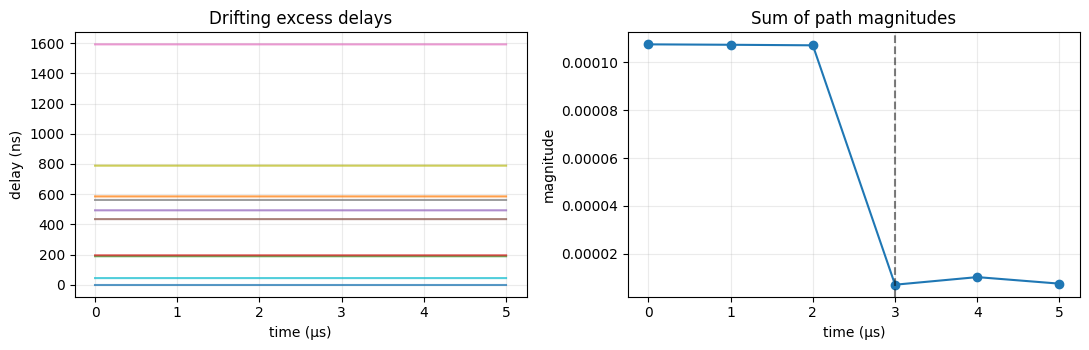

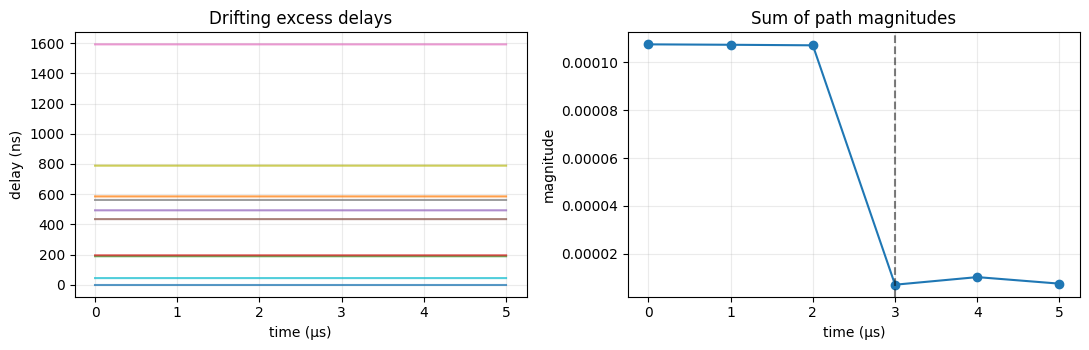

In [3]:
carrier = realization.carriers[0]
rays = carrier.rays
delay_ns = rays.excess_delay_s[0, 0, 0, :, 0, :].detach().cpu().numpy() * 1e9
activity = rays.amplitude_weight[0, 0, 0, :, 0, :].detach().cpu().numpy()
coefficient_magnitude = (
    carrier.cir.coefficients[0, 0, 0, 0, 0].abs().detach().cpu().numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for path in range(min(10, delay_ns.shape[0])):
    axes[0].plot(np.asarray(times) * 1e6, delay_ns[path], alpha=0.75)
axes[0].set(title="Drifting excess delays", xlabel="time (µs)", ylabel="delay (ns)")
axes[0].grid(alpha=0.25)

axes[1].plot(
    np.asarray(times) * 1e6,
    coefficient_magnitude.sum(axis=0),
    marker="o",
)
axes[1].axvline(times[3] * 1e6, color="black", linestyle="--", alpha=0.5)
axes[1].set(title="Sum of path magnitudes", xlabel="time (µs)", ylabel="magnitude")
axes[1].grid(alpha=0.25)
fig.tight_layout()

active_per_time = (activity > 0.0).sum(axis=0)
print("Active ray-slot counts:", active_per_time.tolist())
print("Maximum geometric solver residual (m):", float(carrier.diagnostics["solver_residual_m"].max()))
fig

## 3. Convert the dynamic CIR to OFDM and sampled time

Both transforms consume the time-varying path delay at its matching output
sample. The RMS delay-spread metric likewise retains the time axis.

In [4]:
frequencies_hz = torch.linspace(-7.5e6, 7.5e6, 64, dtype=torch.float64)
ofdm = cir_to_ofdm(carrier.cir, frequencies_hz)
sampled = cir_to_time(carrier.cir, 100.0e6)
delay_spread_ns = rms_delay_spread(carrier.cir) * 1e9

print("OFDM response shape:", tuple(ofdm.shape))
print("Sampled-time response shape:", tuple(sampled.shape))
print("RMS delay spread (ns):", delay_spread_ns.flatten().detach().cpu().numpy().round(3).tolist())
assert ofdm.shape[-2:] == (6, 64)
assert sampled.shape[-2] == 6
assert delay_spread_ns.shape == (1, 1, 1, 6)

OFDM response shape: (1, 1, 1, 1, 1, 6, 64)
Sampled-time response shape: (1, 1, 1, 1, 1, 6, 297)
RMS delay spread (ns): [205.614, 205.807, 206.08, 206.432, 170.073, 142.09]


## 4. Resume at a segment boundary

The second request starts exactly one sample after the first. Because the RNG
root, lineage, endpoint identities, carrier order, and model digest match, its
output equals the corresponding suffix of the one-shot realization—even
though the LOS-to-NLOS boundary occurs between chunks.

In [5]:
first_request = make_request(times[:3], positions[:3], states[:3])
first = model.realize(first_request)
second_request = make_request(
    times[3:],
    positions[3:],
    states[3:],
    prior_state=first.state,
)
second = model.realize(second_request)

for carrier_index, resumed_carrier in enumerate(second.carriers):
    expected = realization.carriers[carrier_index].cir.coefficients[..., 3:]
    torch.testing.assert_close(resumed_carrier.cir.coefficients, expected)

print("First chunk final time (µs):", first.state.last_time_s * 1e6)
print("Resumed final time (µs):", second.state.last_time_s * 1e6)
print("Resumed generation IDs:", torch.unique(second.state.carrier_states[0].generation_ids).tolist())
print("Maximum one-shot/resumed error:", float(
    (second.carriers[0].cir.coefficients - realization.carriers[0].cir.coefficients[..., 3:]).abs().max()
))

First chunk final time (µs): 2.0
Resumed final time (µs): 5.0
Resumed generation IDs: [1]
Maximum one-shot/resumed error: 7.102587184659786e-22


## 5. Persist and reload the dynamic realization

Persistence includes every carrier, ray trajectory, large-scale trajectory,
checksummed array payload, and the state needed for another continuation.

In [6]:
with TemporaryDirectory() as directory:
    saved = save_geometric_cdl_realization(Path(directory) / "geometric", realization)
    restored = load_geometric_cdl_realization(saved, execution)
    manifest_size = (saved / "manifest.json").stat().st_size

for expected_carrier, actual_carrier in zip(
    realization.carriers, restored.carriers, strict=True
):
    torch.testing.assert_close(actual_carrier.cir.coefficients, expected_carrier.cir.coefficients)
    torch.testing.assert_close(actual_carrier.cir.delays_s, expected_carrier.cir.delays_s)

print("Reloaded carriers:", len(restored.carriers))
print("Manifest bytes:", manifest_size)
print("State digest preserved:", restored.state.model_digest == realization.state.model_digest)
assert restored.state.last_time_s == realization.state.last_time_s

Reloaded carriers: 2
Manifest bytes: 37100
State digest preserved: True


## Manual checks and next experiments

- Switch `standard_version` between `16.1.0` and `19.2.0` in the YAML profile.
- Try `initialization_mode: fixed_profile` with CDL-A through CDL-E.
- Compare `legacy` and `laplacian` subpath placement.
- Enable ground reflection for a compatible LOS scenario.
- Replace the scenario boundary with explicit boundaries or a short
  stationarity distance.
- Change the carrier list and inspect shared cluster identities versus
  carrier-specific phase and delay evolution.
- Use a non-isotropic array profile and vary endpoint orientation.

Keep adjacent displacement below one quarter of the shortest wavelength, and
reuse the same semantic random-stream lineage when resuming a state.